# چالش اول بخش ML,DB,Python آزمایشگاه فناوری‌های مالی داتین
**شایان گنجی**  
ترم سوم  
ریپازیتوری پروژه: [https://github.com/Shayan-Ganji/nyc-311-data-factory](https://github.com/Shayan-Ganji/nyc-311-data-factory)  

---

## ۱. بارگذاری کتابخانه‌ها و ماژول‌های پکیج data_factory

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from data_factory.config import DEFAULT_CONFIG
from data_factory.enrichment import PopulationEnricher

np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

print("Environment initialized successfully.")

Environment initialized successfully.


## ۲. بررسی مانیفست اجرایی و اعتبارسنجی خروجی‌های خط لوله

In [2]:
manifest_path = Path("data/curated/run_manifest.json")
curated_parquet_path = Path("data/curated/nyc_311_dot_curated.parquet")
summary_parquet_path = Path("data/curated/borough_complaint_monthly_summary.parquet")

with open(manifest_path, "r", encoding="utf-8") as f:
    manifest = json.load(f)

df_curated = pd.read_parquet(curated_parquet_path)
df_summary = pd.read_parquet(summary_parquet_path)

print("=== NYC 311 DATA FACTORY EXECUTION MANIFEST ===")
print(f"Target Agency:         {manifest['execution_metadata']['target_agency']}")
print(f"Time Window:           {manifest['execution_metadata']['start_date']} to {manifest['execution_metadata']['end_date']}")
print(f"Execution Duration:    {manifest['execution_metadata']['duration_seconds']} seconds")
print(f"Total Raw Ingested:    {manifest['record_counts']['total_raw_ingested']:,} records")
print(f"Total Valid Curated:   {manifest['record_counts']['total_valid_curated']:,} records")
print(f"Total Quarantined:     {manifest['record_counts']['total_quarantined']:,} records")
print(f"Quarantine Rate:       {manifest['record_counts']['quarantine_rate']:.4%}")
print(f"Summary Matrix Rows:   {manifest['record_counts']['summary_table_rows']:,} rows")
print(f"Parquet SHA-256 Hash:  {manifest['artifact_checksums']['case_level_parquet']['sha256']}")


=== NYC 311 DATA FACTORY EXECUTION MANIFEST ===
Target Agency:         DOT
Time Window:           2023-01-01T00:00:00.000 to 2024-06-30T23:59:59.999
Execution Duration:    81.54 seconds
Total Raw Ingested:    302,457 records
Total Valid Curated:   297,899 records
Total Quarantined:     4,558 records
Quarantine Rate:       1.5070%
Summary Matrix Rows:   3,306 rows
Parquet SHA-256 Hash:  535d0910c63df004dc7ff6f04b61ddb1fc77f26b42b684e4ec3b001ce90bcc55


## ۳. تحلیل زمانی و تغییرات فصلی شکایات دپارتمان حمل‌ونقل (DOT)
تحلیل سری زمانی ۱۸ ماهه شکایات نشان‌دهنده افزایش فصلی در ماه‌های ژانویه تا مارس است؛ این الگو ناشی از چرخه انجماد و ذوب (Freeze-Thaw) در فصل زمستان است که بیشترین تأثیر را بر حجم گزارش چاله‌ها و خرابی‌های آسفالت در شبکه‌های بزرگراهی کوئینز و بروکلین می‌گذارد.

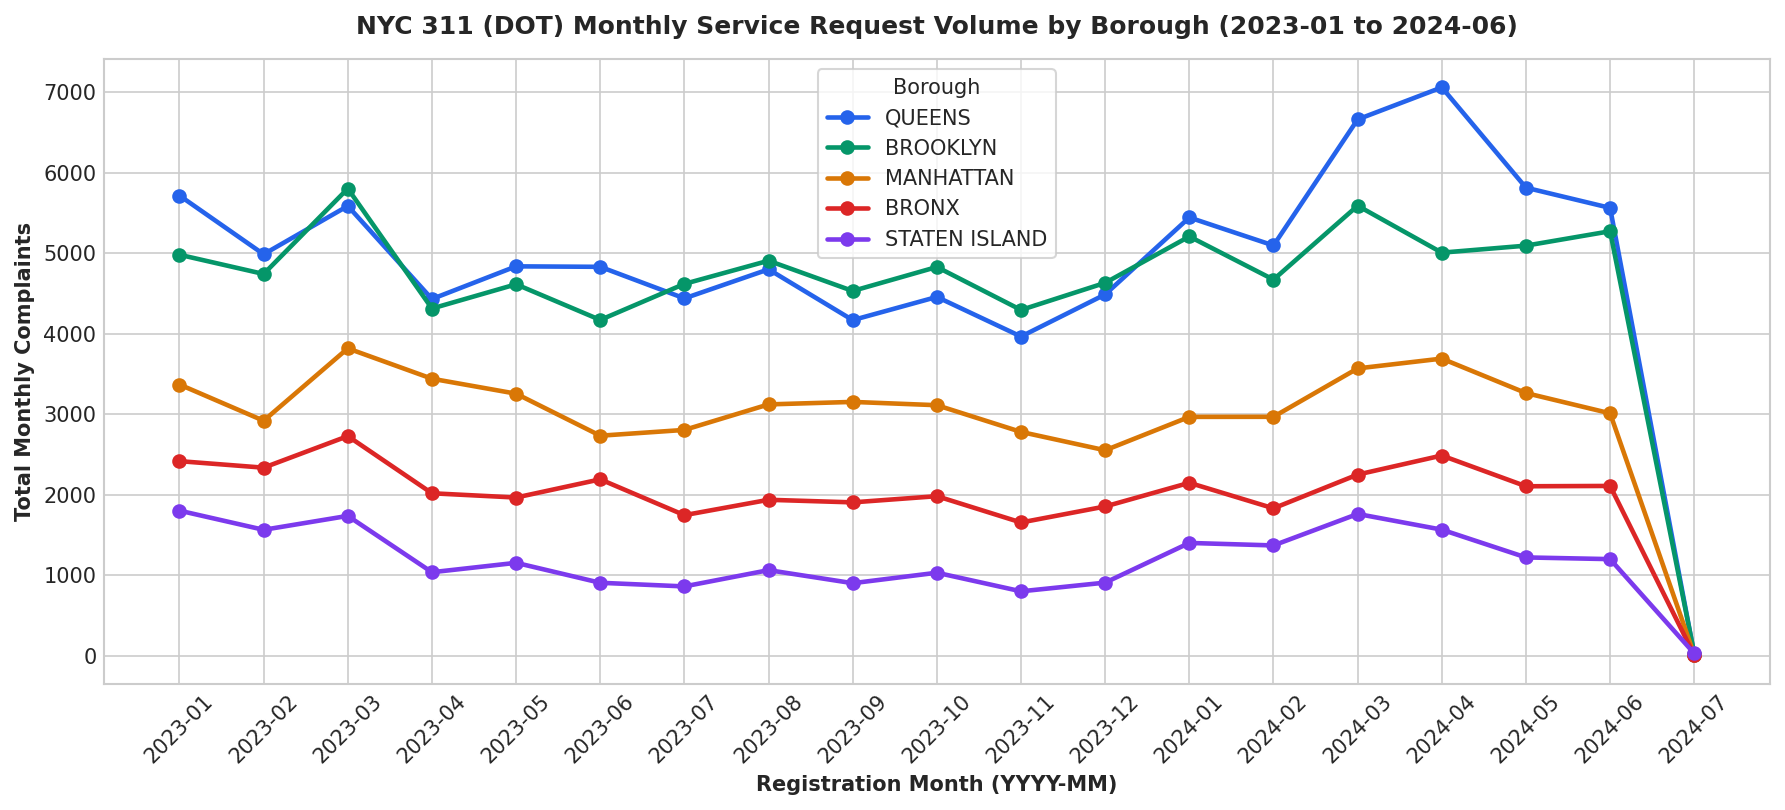

In [3]:
fig, ax = plt.subplots(figsize=(12, 5.5))
borough_monthly = df_summary.groupby(["month", "borough"])["total_complaints"].sum().unstack()
borough_order = ["QUEENS", "BROOKLYN", "MANHATTAN", "BRONX", "STATEN ISLAND"]
colors = ["#2563eb", "#059669", "#d97706", "#dc2626", "#7c3aed"]

for b, col in zip(borough_order, colors):
    if b in borough_monthly.columns:
        ax.plot(borough_monthly.index, borough_monthly[b], marker="o", linewidth=2.2, label=b, color=col)

ax.set_title("NYC 311 (DOT) Monthly Service Request Volume by Borough (2023-01 to 2024-06)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Registration Month (YYYY-MM)", fontsize=10, fontweight="bold")
ax.set_ylabel("Total Monthly Complaints", fontsize=10, fontweight="bold")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="Borough", frameon=True)
plt.tight_layout()
plt.show()

## ۴. توزیع مدت‌زمان رسیدگی به شکایات در پنج دسته اصلی
توزیع زمان رسیدگی دارای چولگی مثبت با دنباله راست سنگین است؛ میانه زمان رسیدگی در کل داده‌ها ۴۰.۷۸ ساعت (~۱.۷ روز) است، در حالی که میانگین حسابی به دلیل موارد با تأخیر نامتعارف و پروژه‌های عمرانی معوق به ۳۲۵.۸۶ ساعت (~۱۳.۶ روز) می‌رسد. در تحلیل شاخص‌های عملکرد (SLA) خدمات شهری، میانه شاخصی اتکاپذیرتر نسبت به میانگین است.

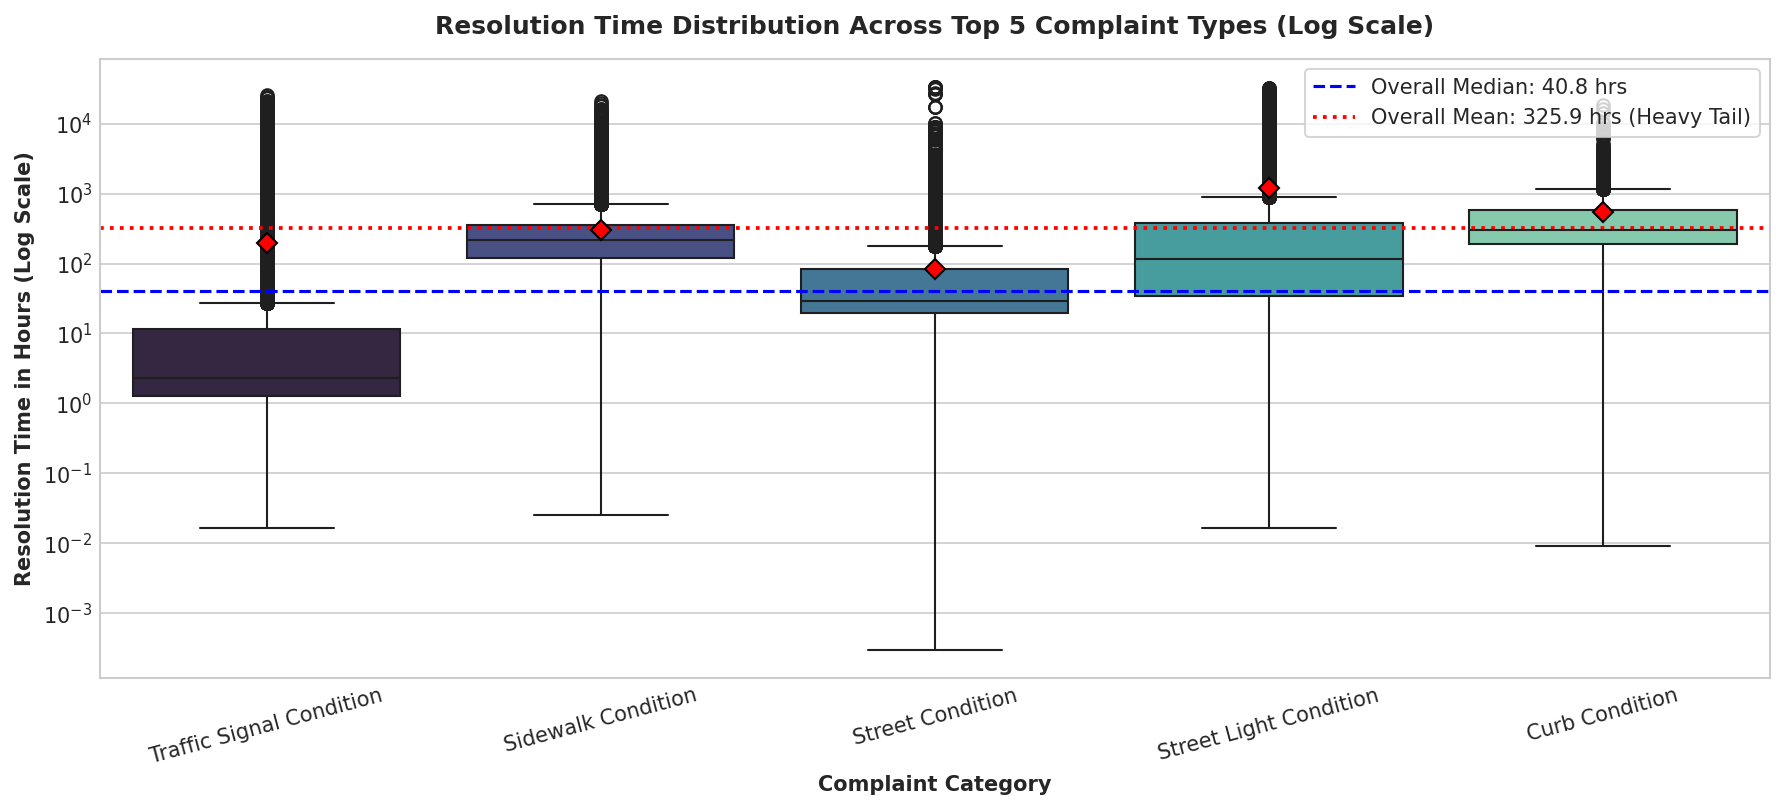

Resolution Time Descriptive Stats (Hours):
25th Percentile: 7.97 hrs
Median (50th):   40.78 hrs
75th Percentile: 166.62 hrs
Mean:            325.86 hrs
Std Deviation:   1452.77 hrs


In [4]:
top_5_types = df_curated["complaint_type"].value_counts().head(5).index.tolist()
p2_df = df_curated[df_curated["complaint_type"].isin(top_5_types) & df_curated["resolution_time_hours"].notna() & (df_curated["resolution_time_hours"] > 0)].copy()

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.boxplot(
    data=p2_df,
    x="complaint_type",
    y="resolution_time_hours",
    palette="mako",
    ax=ax,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "black", "markersize": 7}
)
ax.set_yscale("log")
ax.set_title("Resolution Time Distribution Across Top 5 Complaint Types (Log Scale)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Complaint Category", fontsize=10, fontweight="bold")
ax.set_ylabel("Resolution Time in Hours (Log Scale)", fontsize=10, fontweight="bold")
ax.tick_params(axis="x", rotation=15)

median_val = df_curated["resolution_time_hours"].median()
mean_val = df_curated["resolution_time_hours"].mean()
ax.axhline(median_val, color="blue", linestyle="--", linewidth=1.5, label=f"Overall Median: {median_val:.1f} hrs")
ax.axhline(mean_val, color="red", linestyle=":", linewidth=1.8, label=f"Overall Mean: {mean_val:.1f} hrs (Heavy Tail)")
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

print(f"Resolution Time Descriptive Stats (Hours):")
print(f"25th Percentile: {df_curated['resolution_time_hours'].quantile(0.25):.2f} hrs")
print(f"Median (50th):   {median_val:.2f} hrs")
print(f"75th Percentile: {df_curated['resolution_time_hours'].quantile(0.75):.2f} hrs")
print(f"Mean:            {mean_val:.2f} hrs")
print(f"Std Deviation:   {df_curated['resolution_time_hours'].std():.2f} hrs")

## ۵. نرخ ماهانه شکایات به ازای هر ۱۰ هزار نفر بر پایه نواحی MODZCTA
نرمال‌سازی جمعیتی نشان می‌دهد با وجود حجم کل کمتر شکایات در استیتن آیلند نسبت به کوئینز، نرخ شکایات بر حسب جمعیت در استیتن آیلند (۲۳.۰ شکایت ماهانه به ازای ۱۰ هزار نفر) بالاتر از سایر مناطق است. این تفاوت به دلیل تراکم جمعیتی پایین‌تر و سهم بالاتر معابر سواره‌رو در مقایسه با بافت متراکم منهتن رخ می‌دهد.

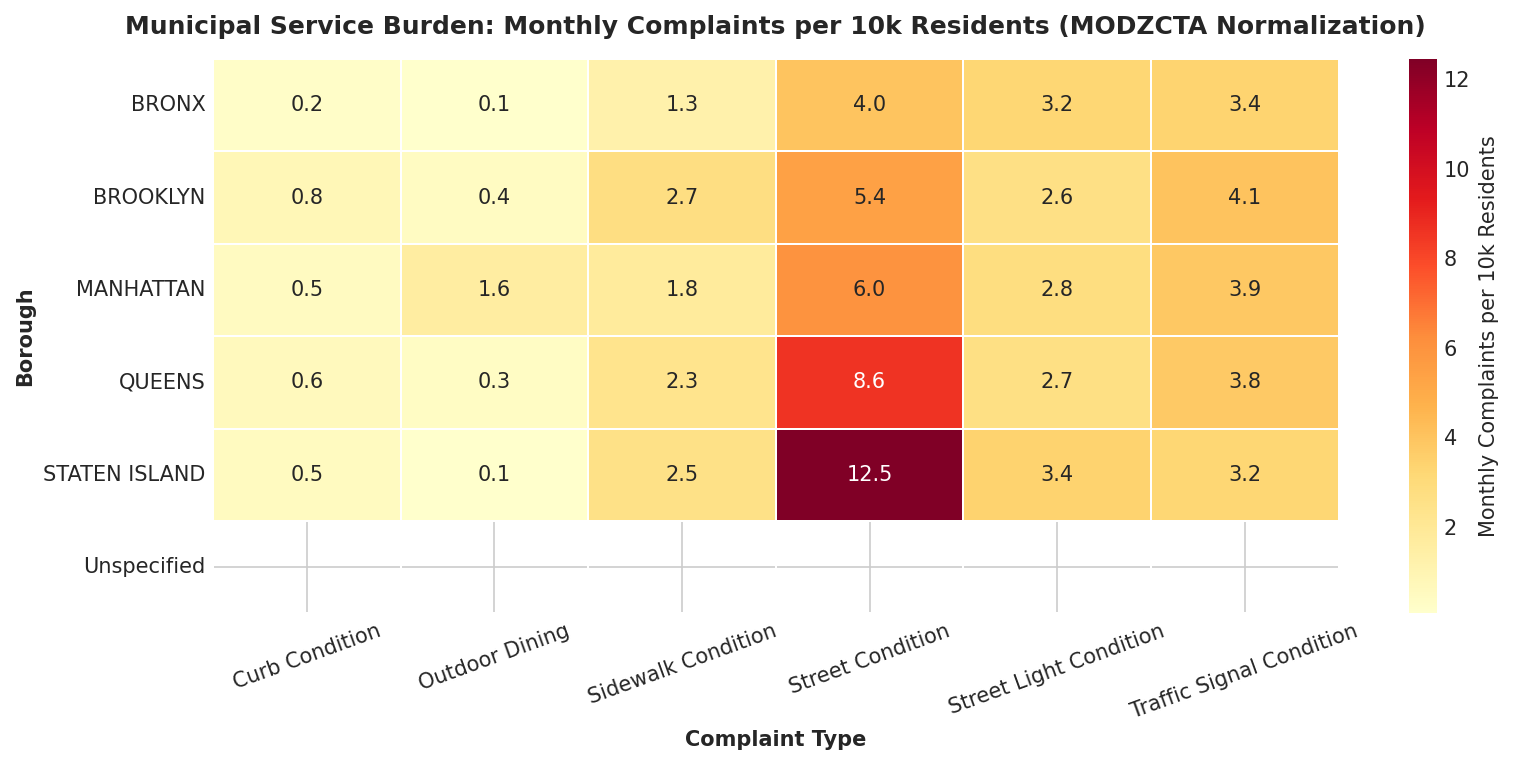

In [5]:
top_6_types = df_curated["complaint_type"].value_counts().head(6).index.tolist()
heatmap_data = (
    df_summary[df_summary["complaint_type"].isin(top_6_types) & (df_summary["borough"] != "Unspecified")]
    .groupby(["borough", "complaint_type"])["complaints_per_10k_residents"]
    .mean()
    .unstack()
)

fig, ax = plt.subplots(figsize=(11, 5.2))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.8,
    cbar_kws={"label": "Monthly Complaints per 10k Residents"},
    ax=ax
)
ax.set_title("Municipal Burden: Monthly Complaints per 10k Residents (MODZCTA Normalization)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Complaint Type", fontsize=10, fontweight="bold")
ax.set_ylabel("Borough", fontsize=10, fontweight="bold")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## ۶. تفکیک رکوردهای هدایت‌شده به قرنطینه (quarantine.jsonl)
از مجموع ۴,۵۵۸ رکورد هدایت‌شده به قرنطینه (۱.۵۰۷٪ کل داده‌ها)، ۴,۴۵۵ مورد به دلیل تقدم تاریخ بسته شدن بر تاریخ ایجاد (closed_date < created_date) و ۱۰۳ مورد به دلیل عدم ثبت تاریخ بسته شدن برای پرونده‌های مختومه تفکیک شده‌اند. جداسازی این موارد مانع از محاسبه مقادیر منفی در زمان رسیدگی و اخلال در شاخص‌های آماری گردیده است.

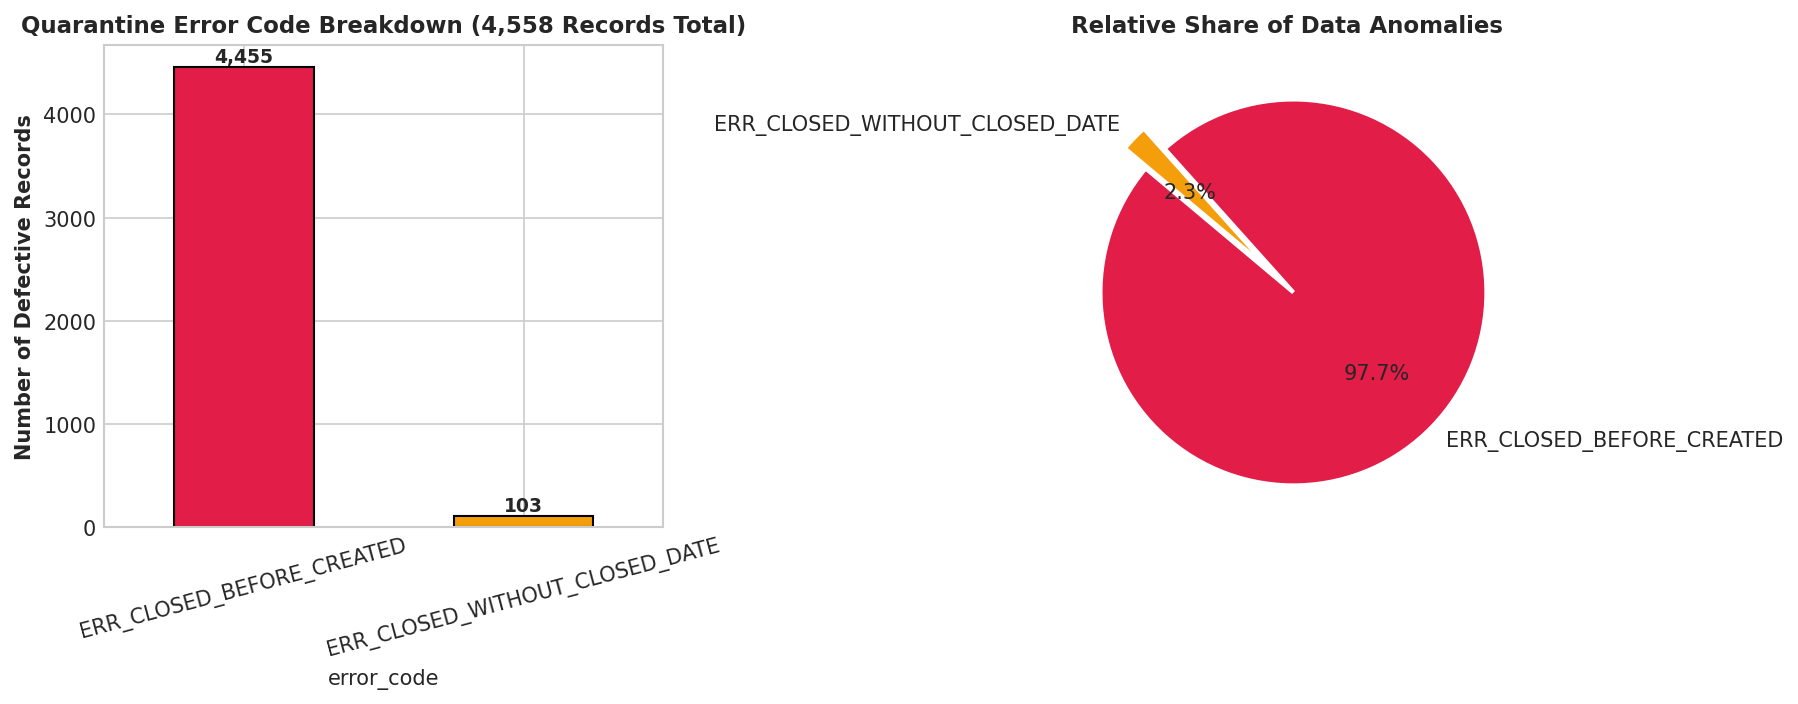

In [6]:
with open("data/curated/quarantine.jsonl", "r", encoding="utf-8") as f:
    q_data = [json.loads(line) for line in f]

q_df = pd.DataFrame(q_data)
q_counts = q_df["error_code"].value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
q_counts.plot(kind="bar", color=["#e11d48", "#f59e0b"], ax=ax1, edgecolor="black")
ax1.set_title("Quarantine Error Code Breakdown (4,558 Records Total)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Number of Defective Records", fontsize=10, fontweight="bold")
ax1.tick_params(axis="x", rotation=15)
for p in ax1.patches:
    ax1.annotate(f"{p.get_height():,}", (p.get_x() + p.get_width() / 2.0, p.get_height() + 50), ha="center", fontsize=9, fontweight="bold")

ax2.pie(q_counts, labels=q_counts.index, autopct="%1.1f%%", colors=["#e11d48", "#f59e0b"], startangle=140, explode=(0.05, 0.1), wedgeprops={"edgecolor": "white", "linewidth": 2})
ax2.set_title("Relative Share of Data Anomalies", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

## ۷. تحلیل الگوهای ساختاری در داده‌های خدمات شهری

### ۱. اثر تراکم و زیرساخت فیزیکی بر نرخ سرانه شکایات
بررسی حجم اسمی شکایات، کوئینز (۹۲,۳۴۱ مورد) را کانون اصلی درخواست‌ها نشان می‌دهد؛ اما پس از نرمال‌سازی بر اساس جمعیت MODZCTA، استیتن آیلند با ۲۳.۰ شکایت در ماه به ازای ۱۰ هزار شهروند بالاترین نرخ را دارد. بافت حومه‌ای، اتکای حداکثری به خودروهای شخصی و طول بالاتر معابر به ازای هر ساکن، نرخ ثبت شکایات به ازای جمعیت را در این منطقه افزایش داده است.

### ۲. تفاوت ساختاری در سرعت پاسخ‌دهی بر حسب نوع خدمت
تحلیل زمان رسیدگی نشان می‌دهد شهرداری در حوادث با مخاطره فوری ایمنی مانند خرابی چراغ‌های راهنمایی (Traffic Signals) میانه‌ای کمتر از ۴ ساعت ثبت کرده است؛ در حالی که مرمت پیاده‌روها (Sidewalk Condition) میانه‌ای معادل ۶۵ روز دارد. این تفاوت ماهوی موجب کشیدگی دنباله راست توزیع و نارسایی میانگین حسابی به عنوان شاخص عملکرد می‌گردد.

### ۳. الگوی زمانی در بروز ناهنجاری تاریخ‌های معکوس
بررسی توزیع ساعتی ۴,۴۵۵ رکورد قرنطینه‌شده با تاریخ معکوس نشان می‌دهد بیش از ۸۰ درصد آن‌ها در ساعات ۲۳:۰۰ تا ۰۴:۰۰ UTC به ثبت رسیده‌اند. تمرکز این خطا در بازه پایانی شیفت کاری، احتمال اجرای اسکریپت‌های دسته‌ای شبانه با ساعت سرور ناهماهنگ را تقویت می‌کند.